In [1]:
import numpy as np
from pathlib import Path
import os, sys
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm
import warnings

repo_root = Path("/home/thardy/elefanto/ConsciousnessTeam_Data/SOUNDMODEL/Data_SoundGOOD/LEAD_ExperimentalFolder")
os.chdir(repo_root)

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))
os.environ["PYTHONPATH"] = str(repo_root) + os.pathsep + os.environ.get("PYTHONPATH", "")

import LEAD as lead


# Important variables
cwd = Path.cwd()
SNRs = np.array([-np.inf,-13,-11,-9,-7,-5,-3])
SubIDs = ['01','02','03','05','06','07','08','09','11','12','13','14','15','17','19','20','22','23','24','25']
colormap = {0: (0, 0, 0), 1: (0, 0.25, 1), 2: (0, 0.9375, 1), 3: (0, 0.91, 0.1), 4: (1, 0.6, 0), 5: (1, 0, 0), 6: (0.8, 0, 0)}

In [2]:
%pip install --force-reinstall --no-deps --no-cache-dir "leadyna[eeg,viz] @ git+https://github.com/ThoHardy/LEADyna.git"

  Cloning https://github.com/ThoHardy/LEADyna.git to /tmp/pip-install-2arvnkj9/leadyna_1e1ebd2529774a2884cf59df339eeac7
  Running command git clone --filter=blob:none --quiet https://github.com/ThoHardy/LEADyna.git /tmp/pip-install-2arvnkj9/leadyna_1e1ebd2529774a2884cf59df339eeac7
  Resolved https://github.com/ThoHardy/LEADyna.git to commit 3989c3726482caf7af9010b4012eb4d25a8b07b4
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for leadyna: filename=leadyna-0.1.0-py3-none-any.whl size=33548 sha256=d0c69cb5de49804c8c5f9387bef24a5334cd57b14aa9c3c867af43141b3e2e78
  Stored in directory: /tmp/pip-ephem-wheel-cache-kwywt8vu/wheels/db/b8/09/c949cab8386917eefee75aed46c64bb269ef3875933e161015
Successfully built leadyna
  Attempting uninstall: leadyna
    Found existing installation: leadyna 0.1.0
    Uninstalling leadyna-0.1.0:
      Successfully uninstalled leadyna-0.1.0

[notice] A new rele

  0%|          | 0/20 [00:00<?, ?it/s]

max_threshold = 1.351 |
 gainmodul threshold = 1.347 |
 nonlinear threshold = 1.351 |


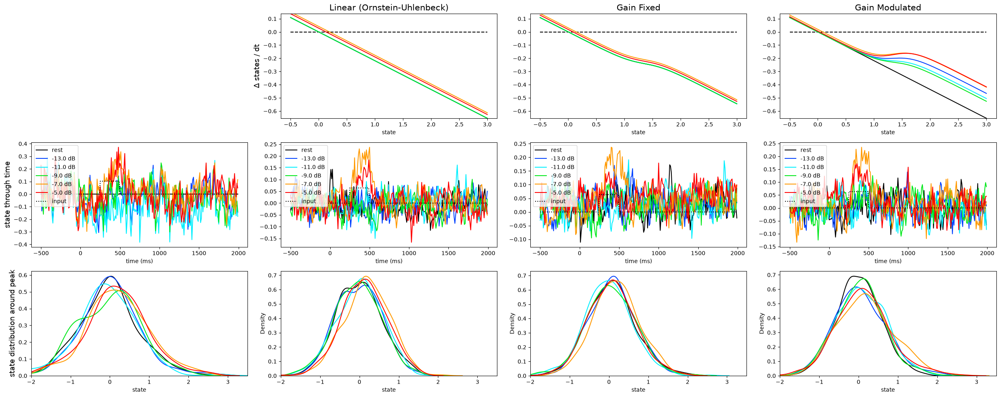

max_threshold = 1.446 |
 gainmodul threshold = 0.801 |
 nonlinear threshold = 1.362 |


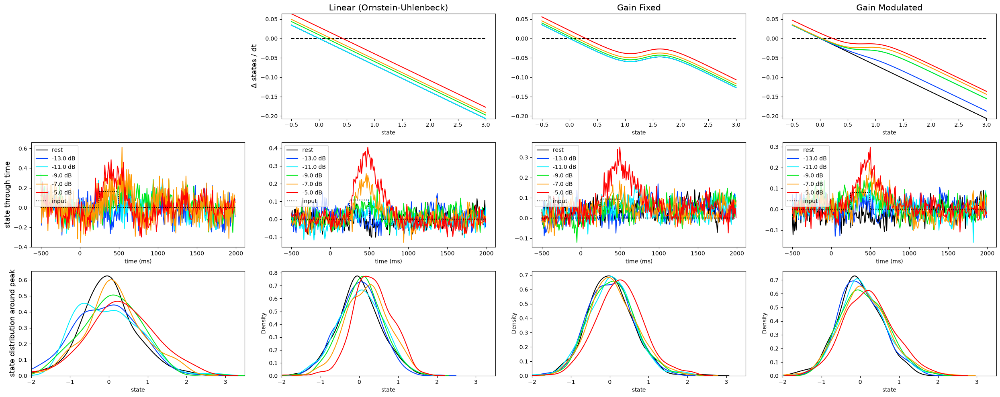

max_threshold = 1.653 |
 gainmodul threshold = 1.286 |
 nonlinear threshold = 1.653 |


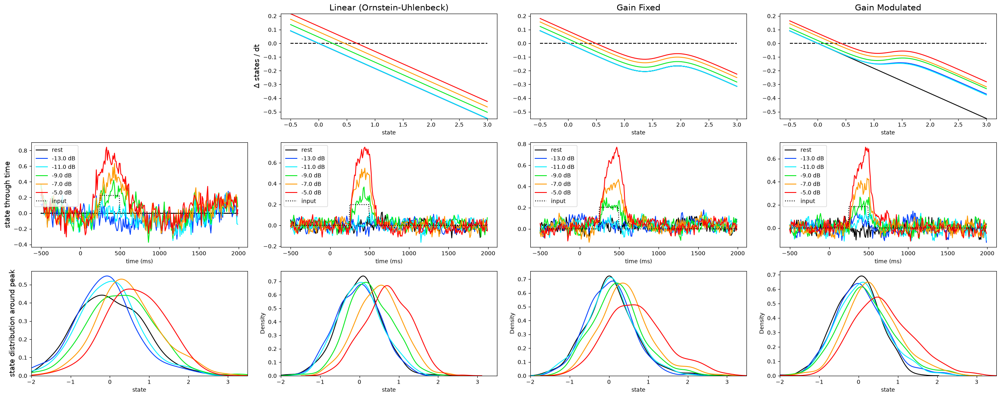

max_threshold = 1.597 |
 gainmodul threshold = 0.812 |
 nonlinear threshold = 1.518 |


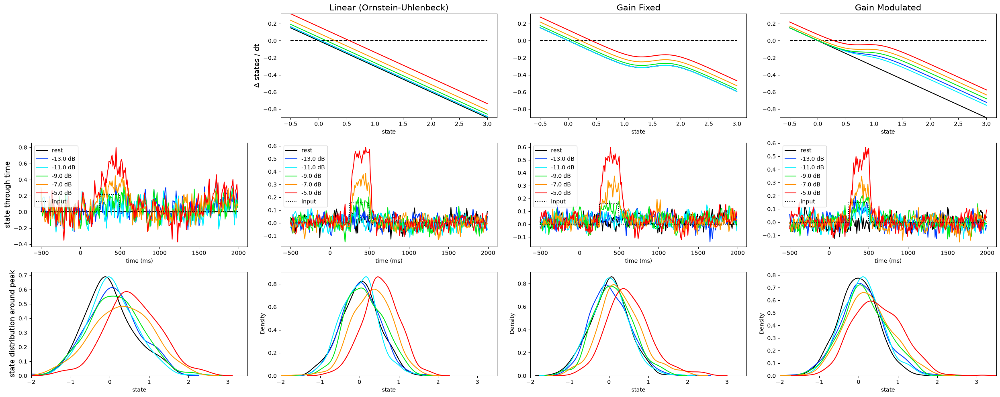

max_threshold = 1.742 |
 gainmodul threshold = 1.355 |
 nonlinear threshold = 1.638 |


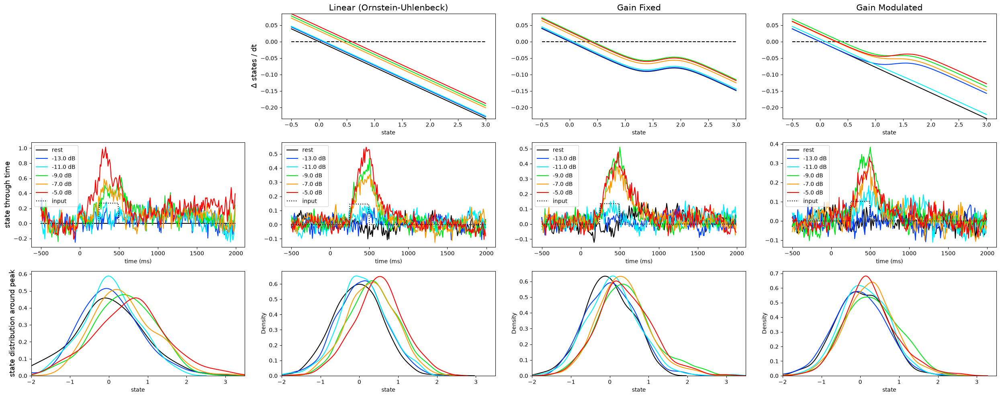

max_threshold = 1.541 |
 gainmodul threshold = 0.334 |
 nonlinear threshold = 1.541 |


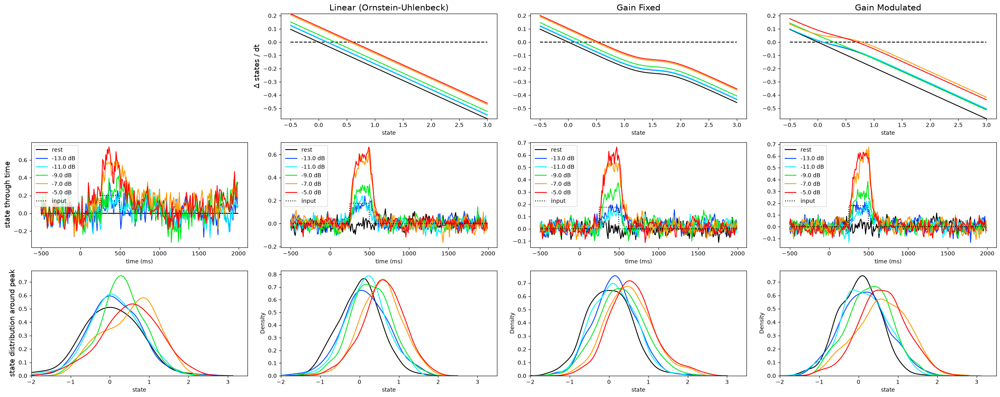

max_threshold = 1.927 |
 gainmodul threshold = 0.980 |
 nonlinear threshold = 1.510 |


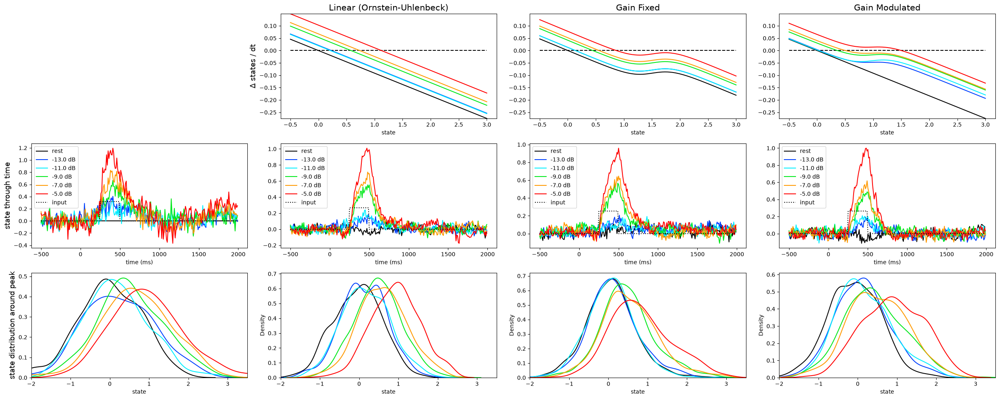

max_threshold = 1.586 |
 gainmodul threshold = 0.813 |
 nonlinear threshold = 1.247 |


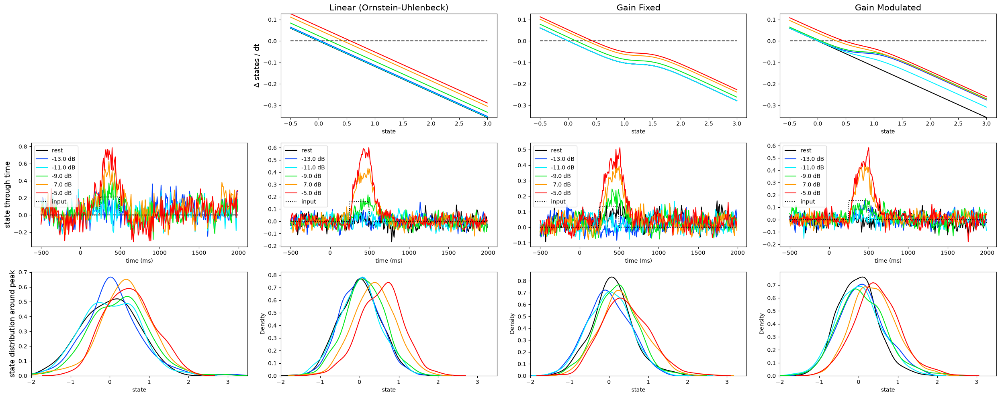

max_threshold = 1.558 |
 gainmodul threshold = 0.441 |
 nonlinear threshold = 1.558 |


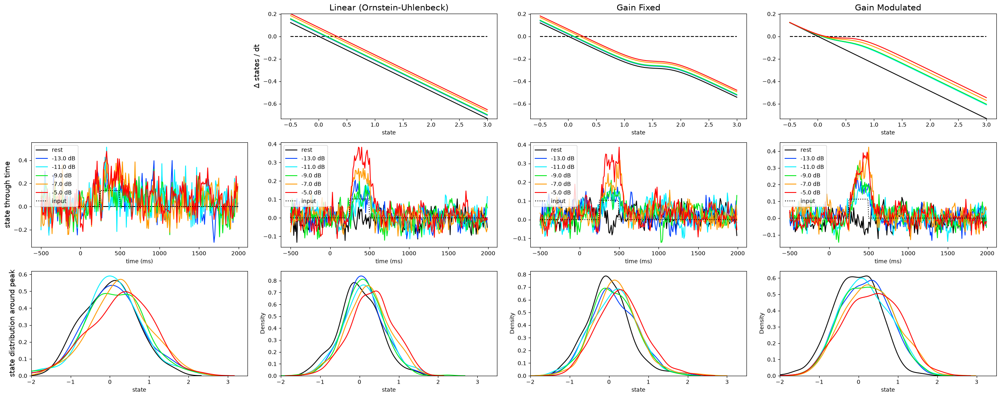

max_threshold = 1.864 |
 gainmodul threshold = 0.854 |
 nonlinear threshold = 1.864 |


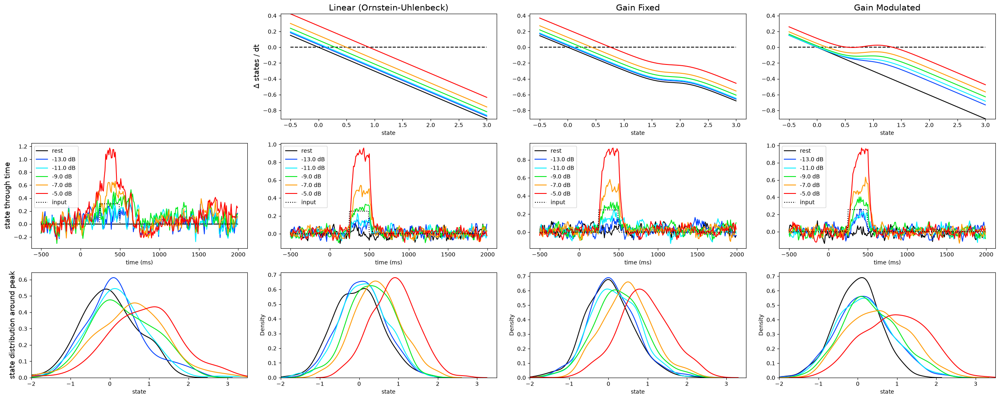

max_threshold = 1.582 |
 gainmodul threshold = 1.198 |
 nonlinear threshold = 1.582 |


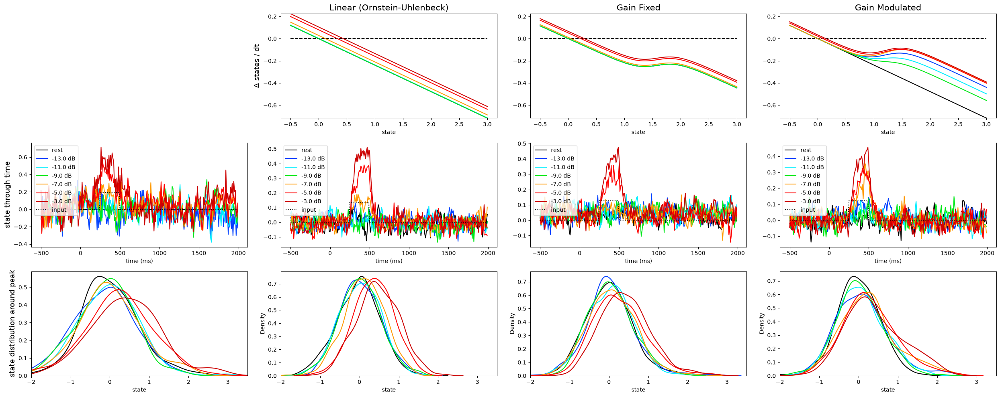

max_threshold = 1.601 |
 gainmodul threshold = 0.847 |
 nonlinear threshold = 1.601 |


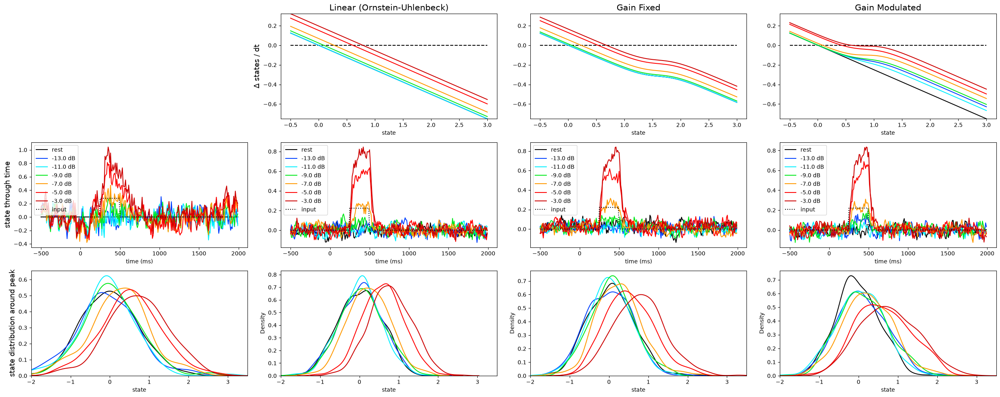

max_threshold = 1.776 |
 gainmodul threshold = 0.830 |
 nonlinear threshold = 1.776 |


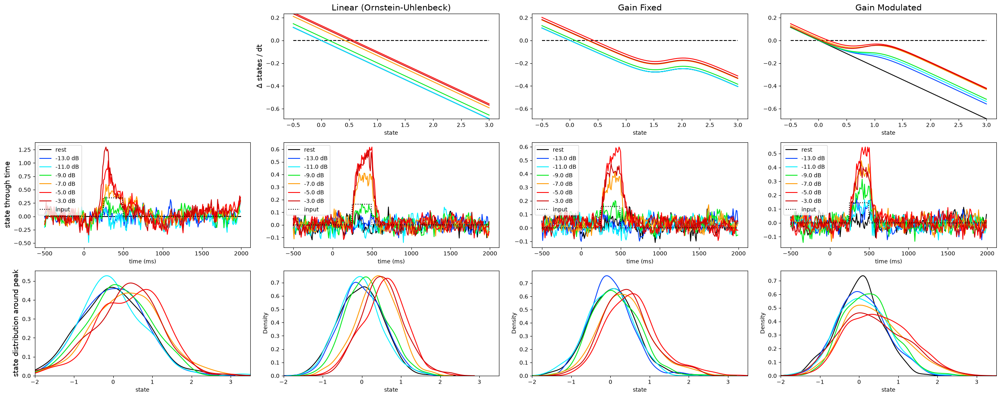

max_threshold = 2.046 |
 gainmodul threshold = 0.951 |
 nonlinear threshold = 1.468 |


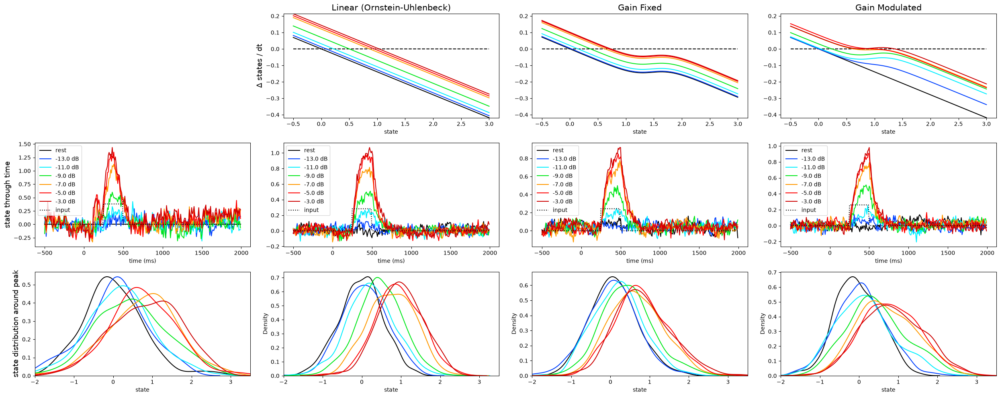

max_threshold = 1.664 |
 gainmodul threshold = 0.482 |
 nonlinear threshold = 1.267 |


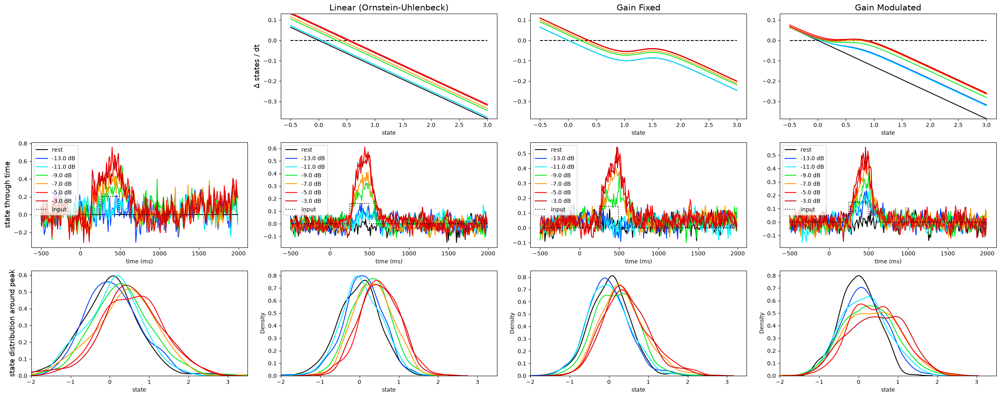

max_threshold = 1.666 |
 gainmodul threshold = 0.472 |
 nonlinear threshold = 1.666 |


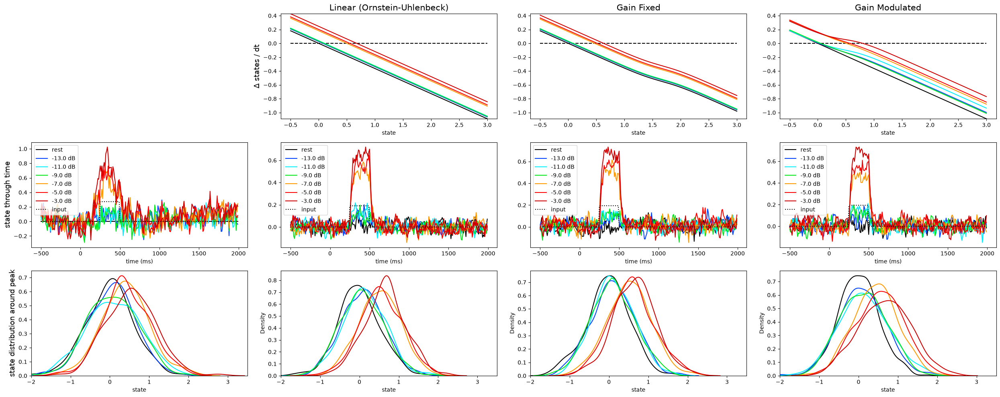

max_threshold = 1.667 |
 gainmodul threshold = 0.442 |
 nonlinear threshold = 1.667 |


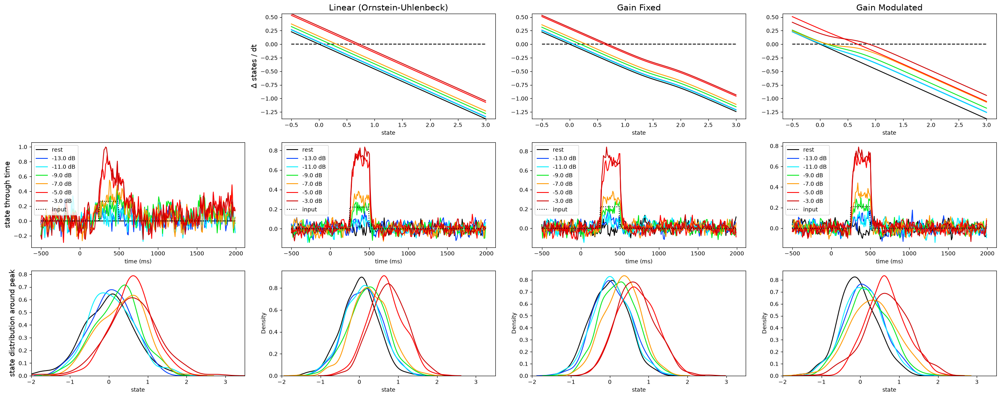

max_threshold = 1.654 |
 gainmodul threshold = 0.803 |
 nonlinear threshold = 1.654 |


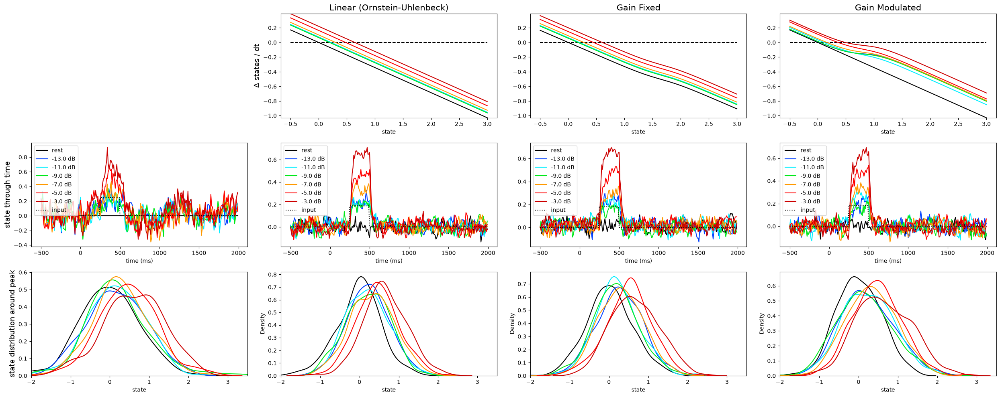

max_threshold = 1.875 |
 gainmodul threshold = 0.929 |
 nonlinear threshold = 1.875 |


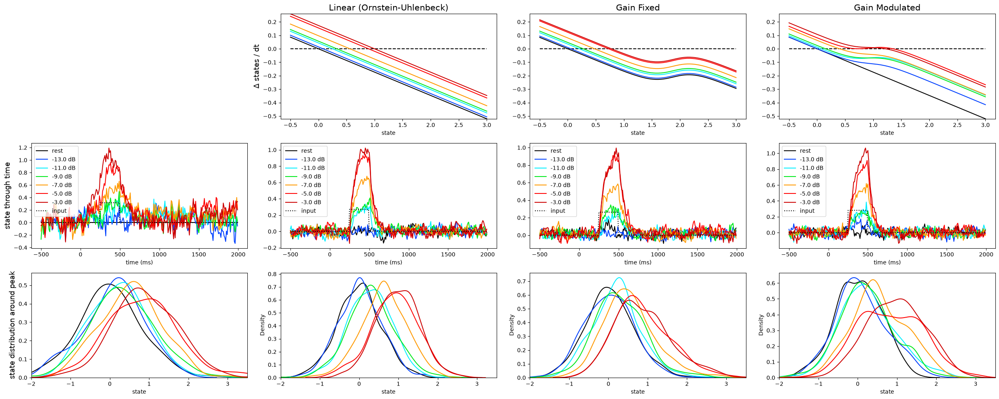

max_threshold = 1.923 |
 gainmodul threshold = 0.517 |
 nonlinear threshold = 1.737 |


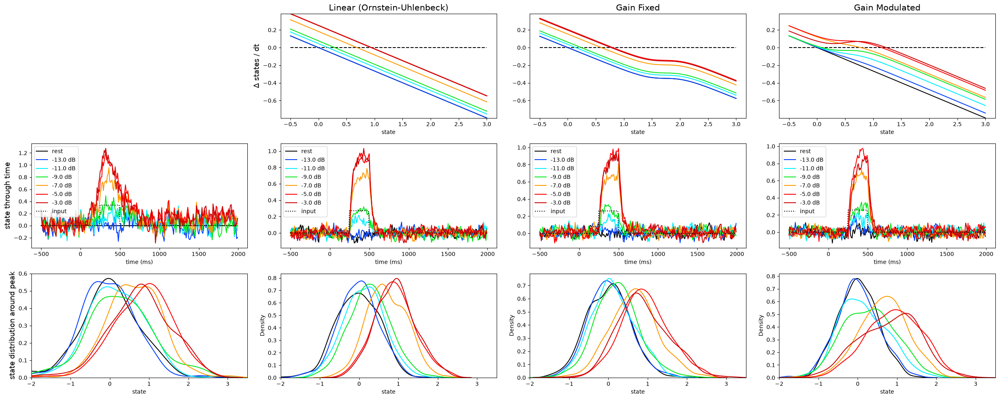

In [12]:
import mne
import leadyna
from leadyna import decode_latent
from leadyna.fitting_tools import clever_fit_gainmodul, clever_fit_linear, clever_fit_nonlinear1

leadyna.BaseLEADModel.baseline_init = "stationary"   # "observation" or "stationary"

task = 'Passive'
file_path = f'Fit_{task}_late_LEADyna_StationaryInit'
os.makedirs(file_path, exist_ok=True)

train_window = (0.3, 0.5)                                   # decoder training window (s)
input_window = (0.25, 0.5)                                  # I(t) = 1 here (s): input hypothesis
peak_window = (input_window[1] - 0.1, input_window[1])      # KDE window: last 100 ms of input
    
for part in tqdm(range(20)):
    
    # Load data
    data_ref = f'myEpochs_{task}/Epoch_{SubIDs[part]}-epo.fif'
    epochs_file = cwd.parents[0] / data_ref
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", category=RuntimeWarning)
        epochs = mne.read_epochs(epochs_file, preload=True, verbose=False)
        epochs.metadata['snr'] = epochs.metadata['snr'] - 1    # recalibrate snr indexes so that 0 corresponds to the no-stim condition
        latent = decode_latent(epochs, train_window=train_window)
    categories = latent.categories
    stim_cats = [cat for cat in categories if cat != 0]
    t = np.round(latent.times, 6)
    in_input = (t >= input_window[0]) & (t < input_window[1])
    in_peak = (t >= peak_window[0]) & (t < peak_window[1])
    pre_stim = t < 0
    seg = int(pre_stim.sum())

    # Input definition (same for all categories & trials)
    one_input = in_input.astype(float)

    # Re-organize to gather baseline windows together (= whole trials with no stim + baseline of trials with a stim)
    rest = latent.states[0]
    no_stim_sliced = np.concatenate([rest[:, i*50:(i+1)*50] for i in range(5)])
    pre_stim_sliced = np.concatenate([latent.states[cat][:, :50] for cat in stim_cats])
    state_train = {0: np.concatenate((no_stim_sliced, pre_stim_sliced))}
    state_train |= {cat: latent.states[cat][:, in_input] for cat in stim_cats}
    input_train = {0: np.zeros_like(state_train[0])}
    input_train |= {cat: np.ones_like(state_train[cat]) for cat in stim_cats}

    # Calibrate max_threshold as th 90th percentile of the states in the training set
    max_threshold = np.percentile(np.concatenate([state_train[cat].flatten() for cat in stim_cats]), 90)

    # ---- Fit Linear ----
    linear = clever_fit_linear(state_train=state_train, input_train=input_train)
    linear.save_params(f'{file_path}/LinearModel_part{part}_params')

    # ---- Fit Gain Modulated ----
    gainmodul = clever_fit_gainmodul(linear_prefitted=linear, state_train=state_train, input_train=input_train, n_loops=2,
                                     bounds={"threshold": (0, max_threshold)})
    gainmodul.save_params(f'{file_path}/GainModulatedModel_part{part}_params')

    # ---- Fit Gain Fixed ----
    nonlinear = clever_fit_nonlinear1(linear_prefitted=linear, state_train=state_train, input_train=input_train, n_loops=2,
                                      bounds={"threshold": (0, max_threshold)})
    nonlinear.save_params(f'{file_path}/GainFixedModel_part{part}_params')

    # Check if threshold bound is reached
    print(f'max_threshold = {max_threshold:.3f} |\n gainmodul threshold = {gainmodul.threshold:.3f} |\n nonlinear threshold = {nonlinear.threshold:.3f} |')

    # ---- Run Simulations from the fitted models  ----
    n_trials = 500
    input_series = {cat: np.tile(one_input, (n_trials, 1)) for cat in categories}
    measures_linear = linear.measure_simulations(input_series=input_series)
    measures_nonlinear = nonlinear.measure_simulations(input_series=input_series)
    measures_gainmodul = gainmodul.measure_simulations(input_series=input_series)
    

    # ---- Plot Results ----
    real = latent.states
    top = stim_cats[-1]
    states = np.linspace(-0.5, 3, 150)
    conditions = [(0, 0)] + [(1, cat) for cat in stim_cats]
    cat_to_db = {cat: SNRs[cat] for cat in stim_cats}
    labels = {cat: 'rest' if cat == 0 else f'{cat_to_db[cat]} dB' for cat in categories}

    plt.figure(figsize=(25, 10))

    models = [
        ("Linear (Ornstein-Uhlenbeck)", linear.core, measures_linear),
        ("Gain Fixed", nonlinear.core, measures_nonlinear),
        ("Gain Modulated", gainmodul.core, measures_gainmodul)
    ]

    # === TOP ROW: Δstate/dt plots ===
    for i, (title, model_func, _) in enumerate(models, start=1):
        plt.subplot2grid((9, 4), (0, i), rowspan=3)
        plt.plot([states[0], states[-1]], [0, 0], linestyle='--', color='black')

        for input_value, signal_category in conditions:
            plt.plot(
                states,
                model_func(states, input_value * np.ones_like(states), signal_category) - states,
                color=colormap[signal_category],
                label=labels[signal_category]
            )

        plt.xlabel('state')
        if i == 1:
            plt.ylabel(r'$\Delta$ states / dt', fontsize=13)
        plt.ylim(float(linear.core(np.array([3.]), np.array([0.]), 0)[0]) - 3,
                 float(linear.core(np.array([-0.5]), np.array([1.]), top)[0]) + 0.5)
        plt.title(title, fontsize=15)

    # === MIDDLE ROW: Time-series plots ===
    time_series_data = [
        ("Real Participant", real),
        ("Linear", measures_linear),
        ("Non-Linear", measures_nonlinear),
        ("Gain Modulation", measures_gainmodul)
    ]
    times = latent.times * 1000

    for i, (title, data_dict) in enumerate(time_series_data):
        plt.subplot2grid((9, 4), (3, i), rowspan=3)

        for cat in categories:
            plt.plot(times, data_dict[cat].mean(0), color=colormap[cat], label=labels[cat])

        ymin, ymax = plt.ylim()
        plt.plot(times, ymax * one_input / 4, color='black', linestyle=':', label='input')

        plt.xlabel('time (ms)')
        if i == 0:
            plt.ylabel('state through time', fontsize=13)
        plt.legend(loc='upper left')

    # === BOTTOM ROW: KDE distributions ===
    xmin, xmax = -2, 3.5
    for i, (title, data_dict) in enumerate(time_series_data):
        plt.subplot2grid((9, 4), (6, i), rowspan=3)

        avgs = {cat: data_dict[cat][:, in_peak].mean(-1) for cat in categories}
        for cat in categories:
            sns.kdeplot(data=avgs[cat], label=labels[cat], color=colormap[cat])

        plt.xlim(xmin, xmax)
        plt.xlabel('state')
        if i == 0:
            plt.ylabel('state distribution around peak', fontsize=13)

    plt.tight_layout()
    plt.savefig(f'{file_path}/AllModels_ad{SubIDs[part]}.png')
    plt.show()

mean_stationary  mean_observation  \
model              param                                              
GainFixedModel     gain                     0.159             0.157   
                   measure_noise            0.614             0.603   
                   process_noise            0.436             0.456   
                   tau                      5.849             5.013   
                   threshold                1.577             1.588   
GainModulatedModel measure_noise            0.614             0.603   
                   process_noise            0.436             0.456   
                   tau                      5.877             4.845   
                   threshold                0.825             0.830   
LinearModel        measure_noise            0.614             0.603   
                   process_noise            0.436             0.456   
                   tau                      5.877             4.845   

                                  median_rel_diff_pct  n_higher_stationary  \
model              param                                                     
GainFixedModel     gain                         1.471                   12   
                   measure_noise                1.696                   20   
                   process_noise               -4.075                    1   
                   tau                          9.143                   20   
                   threshold                    0.000                    4   
GainModulatedModel measure_noise                1.696                   20   
                   process_noise               -4.075                    1   
                   tau                         12.155                   20   
                   threshold                    0.919                   11   
LinearModel        measure_noise                1.696                   20   
                   process_noise               -4.075                    1   
                   tau                         12.155                   20   

                                  max_abs_diff  
model              param                        
GainFixedModel     gain                  0.052  
                   measure_noise         0.030  
                   process_noise         0.085  
                   tau                   3.243  
                   threshold             0.098  
GainModulatedModel measure_noise         0.030  
                   process_noise         0.085  
                   tau                   4.051  
                   threshold             0.293  
LinearModel        measure_noise         0.030  
                   process_noise         0.085  
                   tau                   4.051

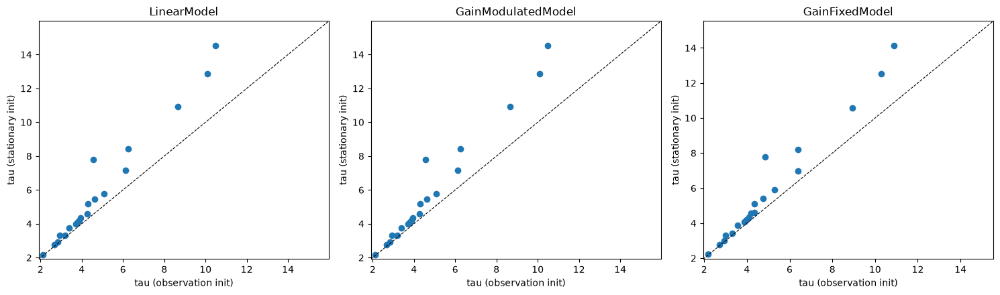

In [13]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

task = 'Passive'
dirs = {'stationary': f'Fit_{task}_late_LEADyna_StationaryInit',
        'observation': f'Fit_{task}_late_LEADyna_ObservationInit'}
models = ['LinearModel', 'GainModulatedModel', 'GainFixedModel']
params = ['tau', 'process_noise', 'measure_noise', 'threshold', 'gain']

rows = []
for model in models:
    for part in range(20):
        p = {init: json.load(open(f'{d}/{model}_part{part}_params')) for init, d in dirs.items()}
        for k in params:
            if k in p['stationary']:
                rows.append(dict(model=model, part=part, param=k,
                                 stationary=p['stationary'][k], observation=p['observation'][k]))
df = pd.DataFrame(rows)
df['diff'] = df['stationary'] - df['observation']
df['rel_diff_%'] = 100 * df['diff'] / df['observation'].abs()

if np.allclose(df['stationary'], df['observation']):
    print('Identical fits: both folders were fitted with the same initialization.')

summary = df.groupby(['model', 'param']).agg(
    mean_stationary=('stationary', 'mean'), mean_observation=('observation', 'mean'),
    median_rel_diff_pct=('rel_diff_%', 'median'), n_higher_stationary=('diff', lambda x: (x > 0).sum()),
    max_abs_diff=('diff', lambda x: x.abs().max()))
display(summary.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, model in zip(axes, models):
    s = df[(df.model == model) & (df.param == 'tau')]
    ax.scatter(s['observation'], s['stationary'])
    lim = [s[['observation', 'stationary']].min().min() * 0.9, s[['observation', 'stationary']].max().max() * 1.1]
    ax.plot(lim, lim, 'k--', lw=0.8)
    ax.set(xlim=lim, ylim=lim, xlabel='tau (observation init)', ylabel='tau (stationary init)', title=model)
plt.tight_layout()
plt.show()

NOTE: plot_psd() is a legacy function. New code should use .compute_psd().plot().


/tmp/ipykernel_469541/545376973.py:1: RuntimeWarning: The measurement information indicates a low-pass frequency of 250.0 Hz. The decim=5 parameter will result in a sampling frequency of 100.0 Hz, which can cause aliasing artifacts.
  epochs_decim = epochs.copy().decimate(5)


    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


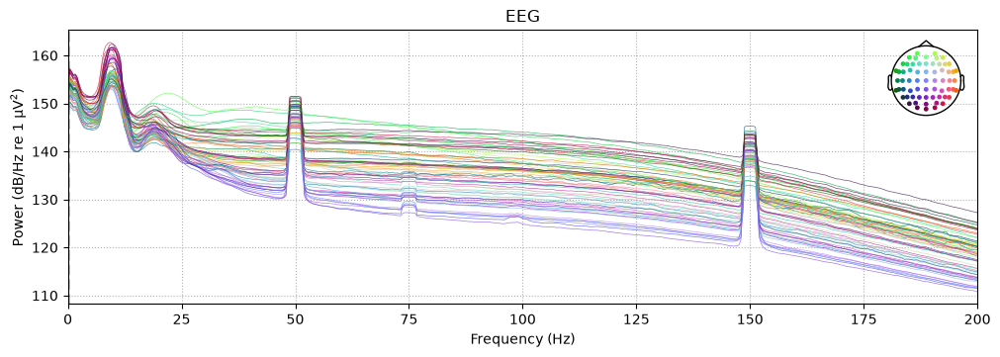

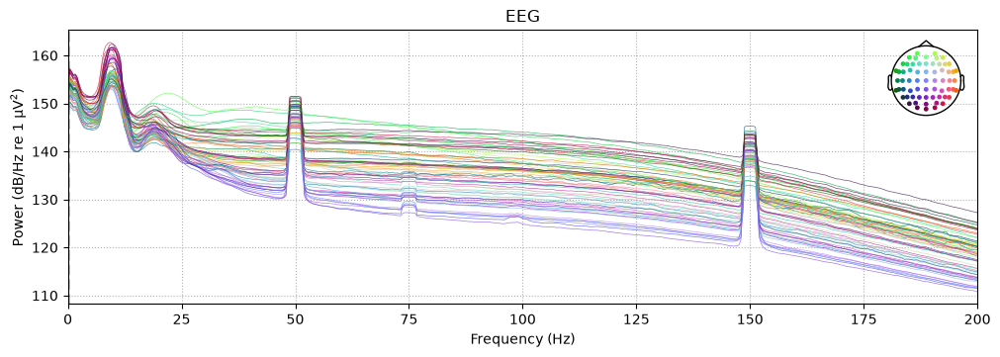

In [23]:
epochs_decim = epochs.copy().decimate(5)
epochs.plot_psd(fmax=200)

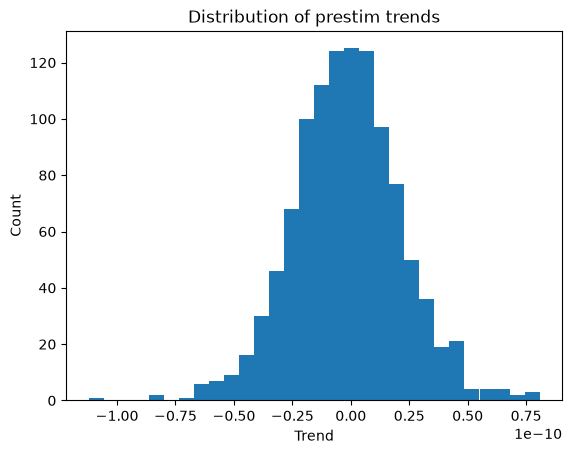

In [24]:
# compute the trend of each trials' prestim period (from -0.2 to 0 s) and plot the distribution of the trends
trends = []
for i in range(len(epochs)):
    prestim_data = epochs.get_data()[i, :, :epochs.time_as_index(0)[0]]
    prestim_trend = np.polyfit(np.arange(prestim_data.shape[1]), prestim_data.mean(axis=0), 1)[0]
    trends.append(prestim_trend)

plt.hist(trends, bins=30)
plt.title('Distribution of prestim trends')
plt.xlabel('Trend')
plt.ylabel('Count')
plt.show()